# Game Trial Design Checks

Encoding-trial mechanics: block conditions, drone/bag trajectories, change-points, fragment distribution, and reward scoring.

In [1]:
import re, json, hashlib, os, math, warnings, textwrap, sys
from pathlib import Path
from datetime import datetime
from collections import Counter, OrderedDict
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from IPython.display import display, HTML

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# Import shared JS parsers
NOTEBOOK_CWD = Path.cwd().resolve()
NOTEBOOK_REPO = next((p for p in [NOTEBOOK_CWD, *NOTEBOOK_CWD.parents]
                      if (p / "index.html").is_file() and (p / "static").is_dir()), None)
if NOTEBOOK_REPO is None:
    raise RuntimeError("Open this notebook from within the DroneTask repository.")
sys.path.insert(0, str(NOTEBOOK_REPO / "design_checks" / "scripts"))
from js_import import (load_sources, parse, save_fig, save_html, apply_style,
                        REPO_ROOT, DESIGN_DIR, FIG_DIR, sha256, load_runtime_design)
apply_style()
get_ipython().run_line_magic("matplotlib", "inline")
print("Notebook interpreter", sys.executable)

# ── Load all JS sources ──
stimuli_src = (REPO_ROOT / "static/task/stimuli.js").read_text() if (REPO_ROOT / "static/task/stimuli.js").exists() else ""
memory_src  = (REPO_ROOT / "static/task/memory_task.js").read_text() if (REPO_ROOT / "static/task/memory_task.js").exists() else ""
details_src = (REPO_ROOT / "static/task/stimuli-details.js").read_text() if (REPO_ROOT / "static/task/stimuli-details.js").exists() else ""
trial_src   = (REPO_ROOT / "static/task/trial.js").read_text() if (REPO_ROOT / "static/task/trial.js").exists() else ""
index_src   = (REPO_ROOT / "index.html").read_text() if (REPO_ROOT / "index.html").exists() else ""

# Re-export original helper functions from the shared module
parse_js_flat_array = parse.flat_array
parse_js_2d_array = parse.array_2d
parse_js_string = parse.string
parse_js_string_array = parse.string_array
parse_js_int_pair_array = parse.int_pair_array

# ── Original helper functions that stay local ──
def read_text(relpath):
    p = REPO_ROOT / relpath
    return p.read_text(encoding="utf-8") if p.exists() else None

def pair_in(pair, plist):
    return any(pair[0] == p[0] and pair[1] == p[1] for p in plist)

def styled_table_css(uid="tbl"):
    return textwrap.dedent(f"""\
    <style>
    #{uid} th {{ background:#f3f3f3; color:#222; font-weight:650;
      border:1px solid #d6d6d6; padding:5px 10px; text-align:left; }}
    #{uid} td {{ border:1px solid #e1e1e1; padding:4px 10px;
      font-variant-numeric:tabular-nums; }}
    #{uid} tr:nth-child(even) td {{ background:#fafafa; }}
    #{uid} table {{ border-collapse:collapse; font-size:12px;
      font-family:-apple-system,BlinkMacSystemFont,'Segoe UI',Arial,sans-serif; }}
    #{uid} caption {{ caption-side:top; padding:4px 0; color:#444;
      font-size:12px; text-align:left; font-weight:600; }}
    </style>
    """)

# save_html is imported from js_import (category-aware)

print("Setup complete.")

# Evaluate the implementation, including participant assignment and clipping.
runtime_design = load_runtime_design()
runtime_variants = runtime_design['variants']
reference_design = runtime_variants[0]  # reward unshifted; both assignments audited below
print('Condition label version', reference_design['condition_label_version'])


Notebook interpreter /Users/yizj/Desktop/Desktop - beaverjuly/InCogLab/DroneTask/.venv-design/bin/python
Setup complete.


Condition label version trajectory-aligned-v2-20261104


## Block condition design

Canonical A and C use smaller drone shifts and larger supply offsets. B and D use larger drone shifts and smaller supply offsets. The numeric factor codes label these relative regimes and do not report empirical variances. The trajectories, valence assignments and Latin order are preserved.


In [2]:
factors_vol = reference_design['factors_vol']
factors_stc = reference_design['factors_stc']
factors_valence = reference_design['factors_valence']
condition_ids = reference_design['condition_ids']
block_df = pd.DataFrame({
    'canonical_condition': np.arange(1,5),
    'condition_id': condition_ids,
    'valence': factors_valence,
    'vol_code': factors_vol,
    'vol_level': [r['vol_level'] for r in reference_design['metrics']],
    'stc_code': factors_stc,
    'stc_level': [r['stc_level'] for r in reference_design['metrics']],
})
display(block_df)
assert factors_vol == [4,49,4,49] and factors_stc == [64,16,64,16]
assert factors_valence == ['reward','reward','loss','loss']
for variant in runtime_variants:
    for i,row in enumerate(variant['metrics']):
        expected = f"{chr(65+i)}_{row['valence']}_{row['vol_level']}Vol_{row['stc_level']}Stc"
        assert variant['condition_ids'][i] == expected
print('Both trajectory assignments match the saved labels. Factor numbers are nominal design codes, not empirical variances.')


,canonical_condition,condition_id,valence,vol_code,vol_level,stc_code,stc_level
0,1,A_reward_lowVol_highStc,reward,4,low,64,high
1,2,B_reward_highVol_lowStc,reward,49,high,16,low
2,3,C_loss_lowVol_highStc,loss,4,low,64,high
3,4,D_loss_highVol_lowStc,loss,49,high,16,low


Both trajectory assignments match the saved labels. Factor numbers are nominal design codes, not empirical variances.


## Reward and loss trajectory assignments

Dotted lines show each unshifted source sequence and solid lines show the arrays actually assembled by the browser code. Both randomized reward and loss shift assignments are executed. Vertical markers show every nonzero change in drone position.


  ✓ game_trials/trajectories_reward_shifted_false.png + .pdf
  ✓ game_trials/trajectories_reward_shifted_false.html


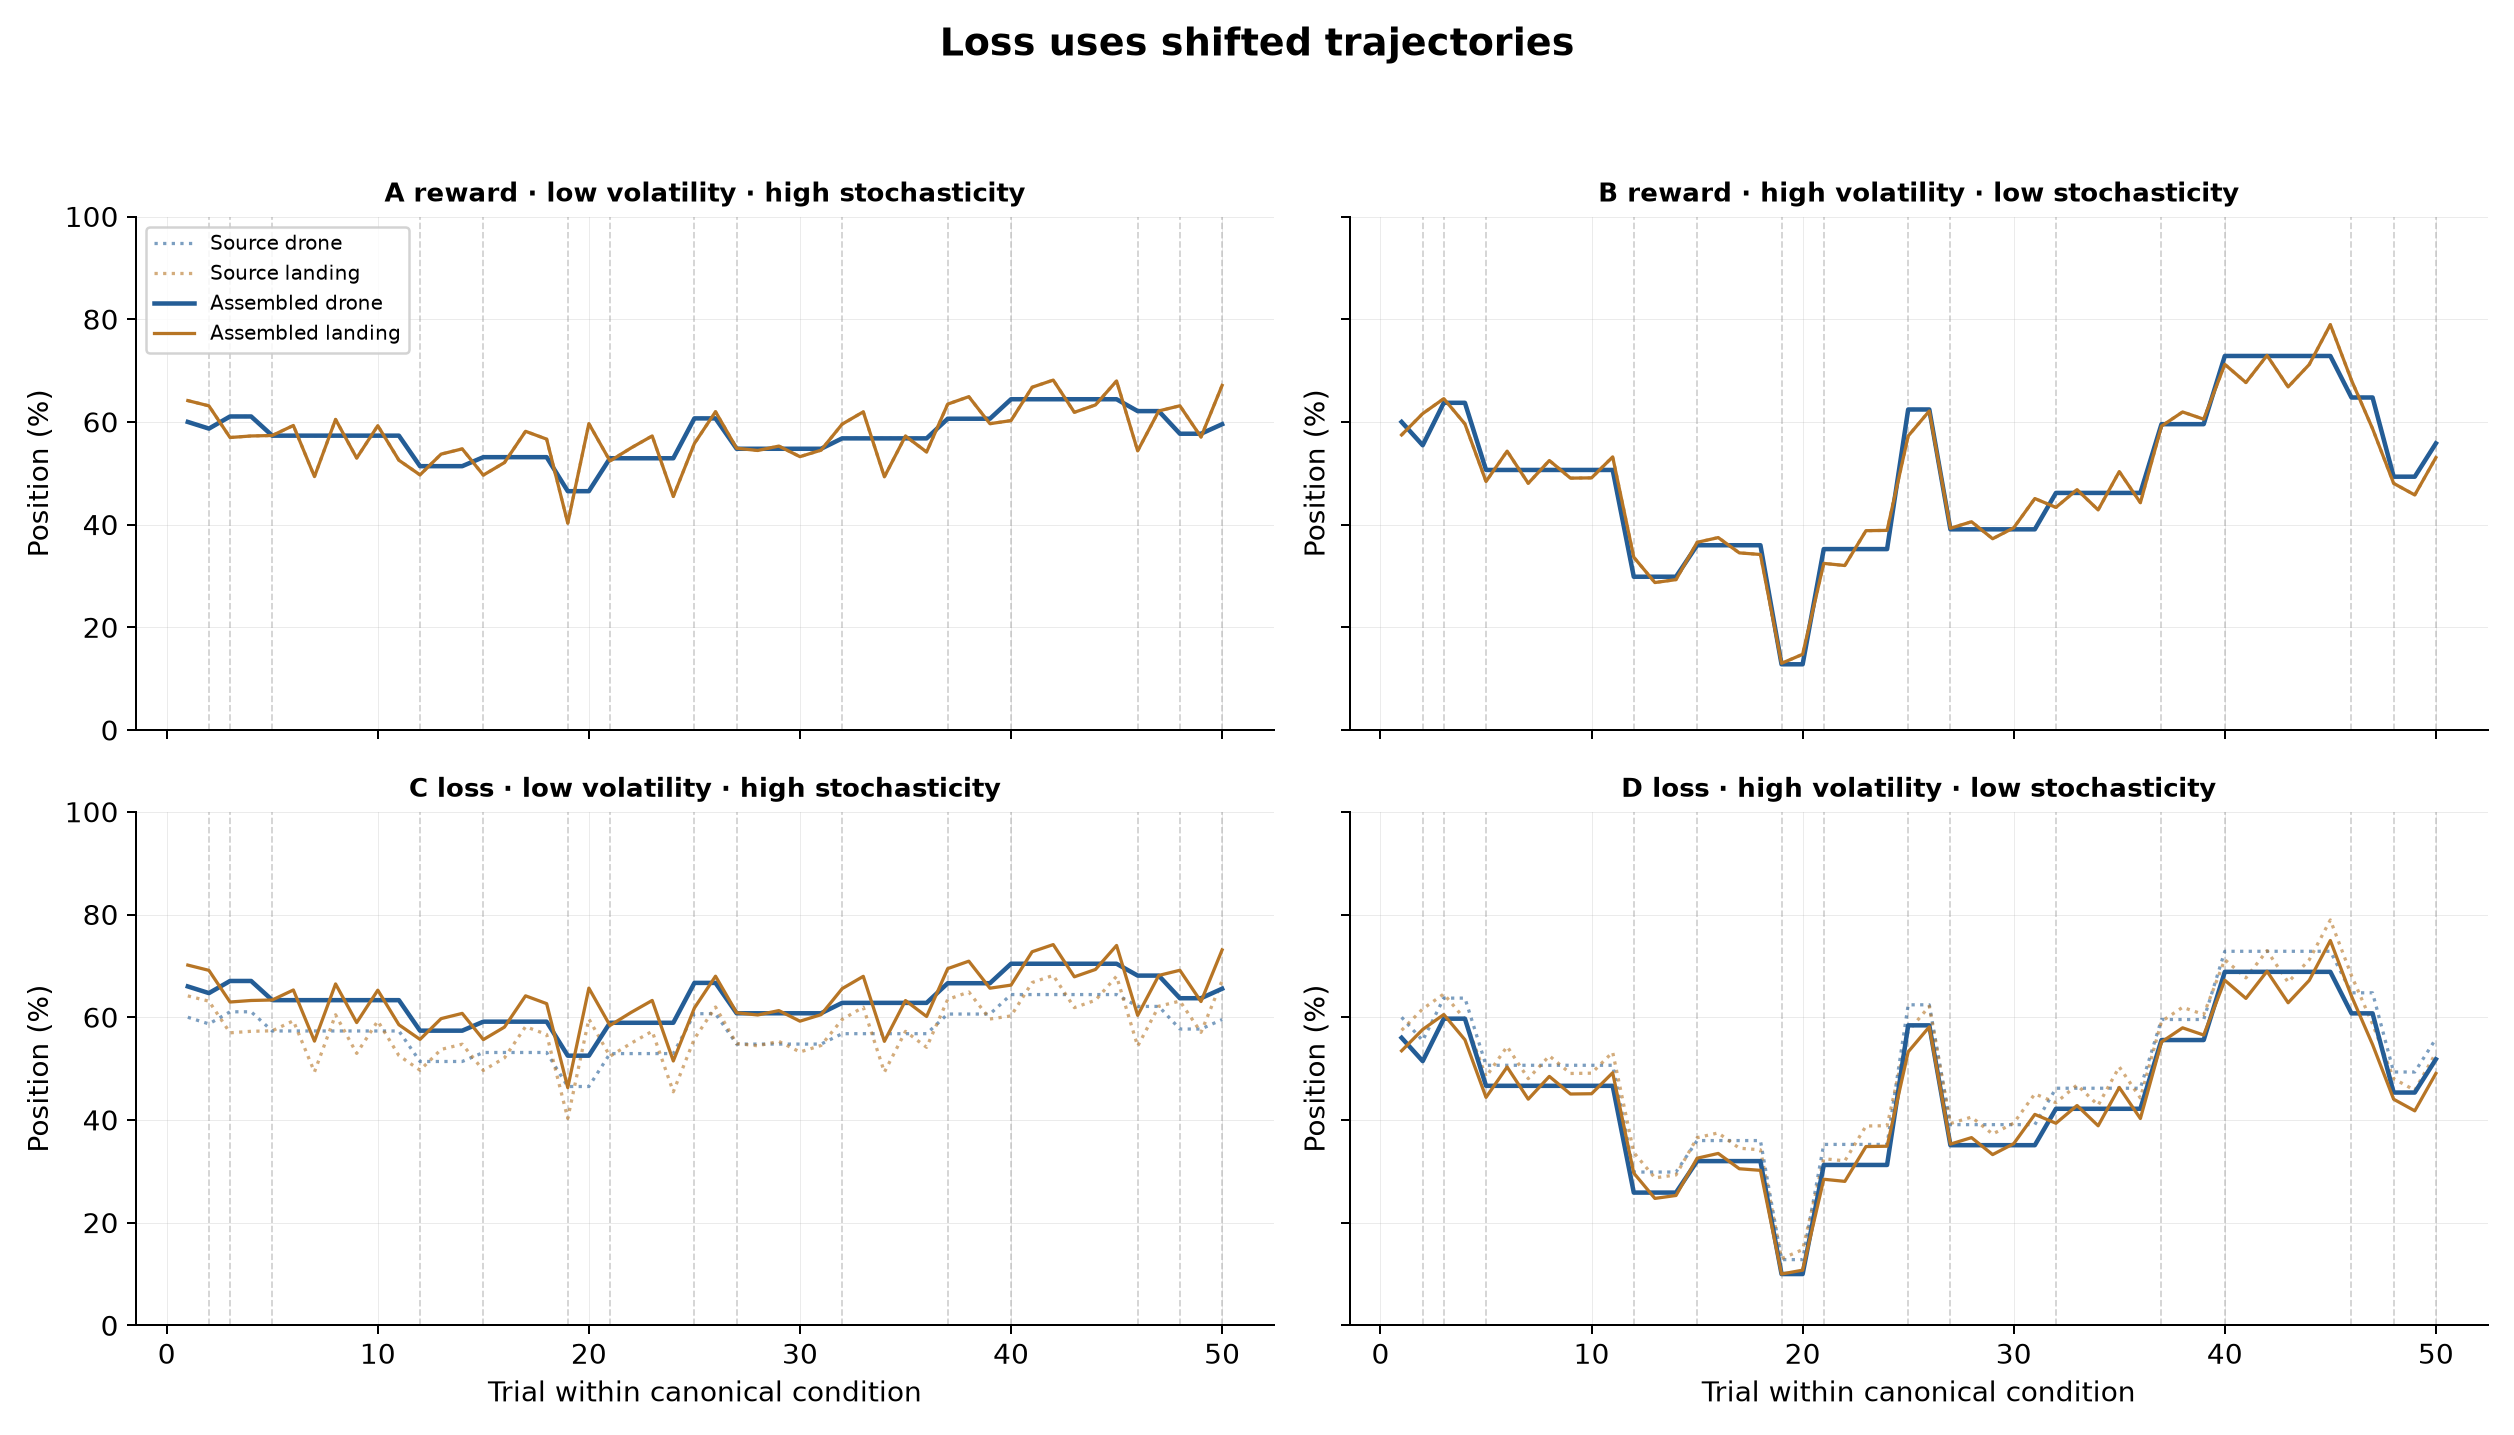

  ✓ game_trials/trajectories_reward_shifted_true.png + .pdf
  ✓ game_trials/trajectories_reward_shifted_true.html


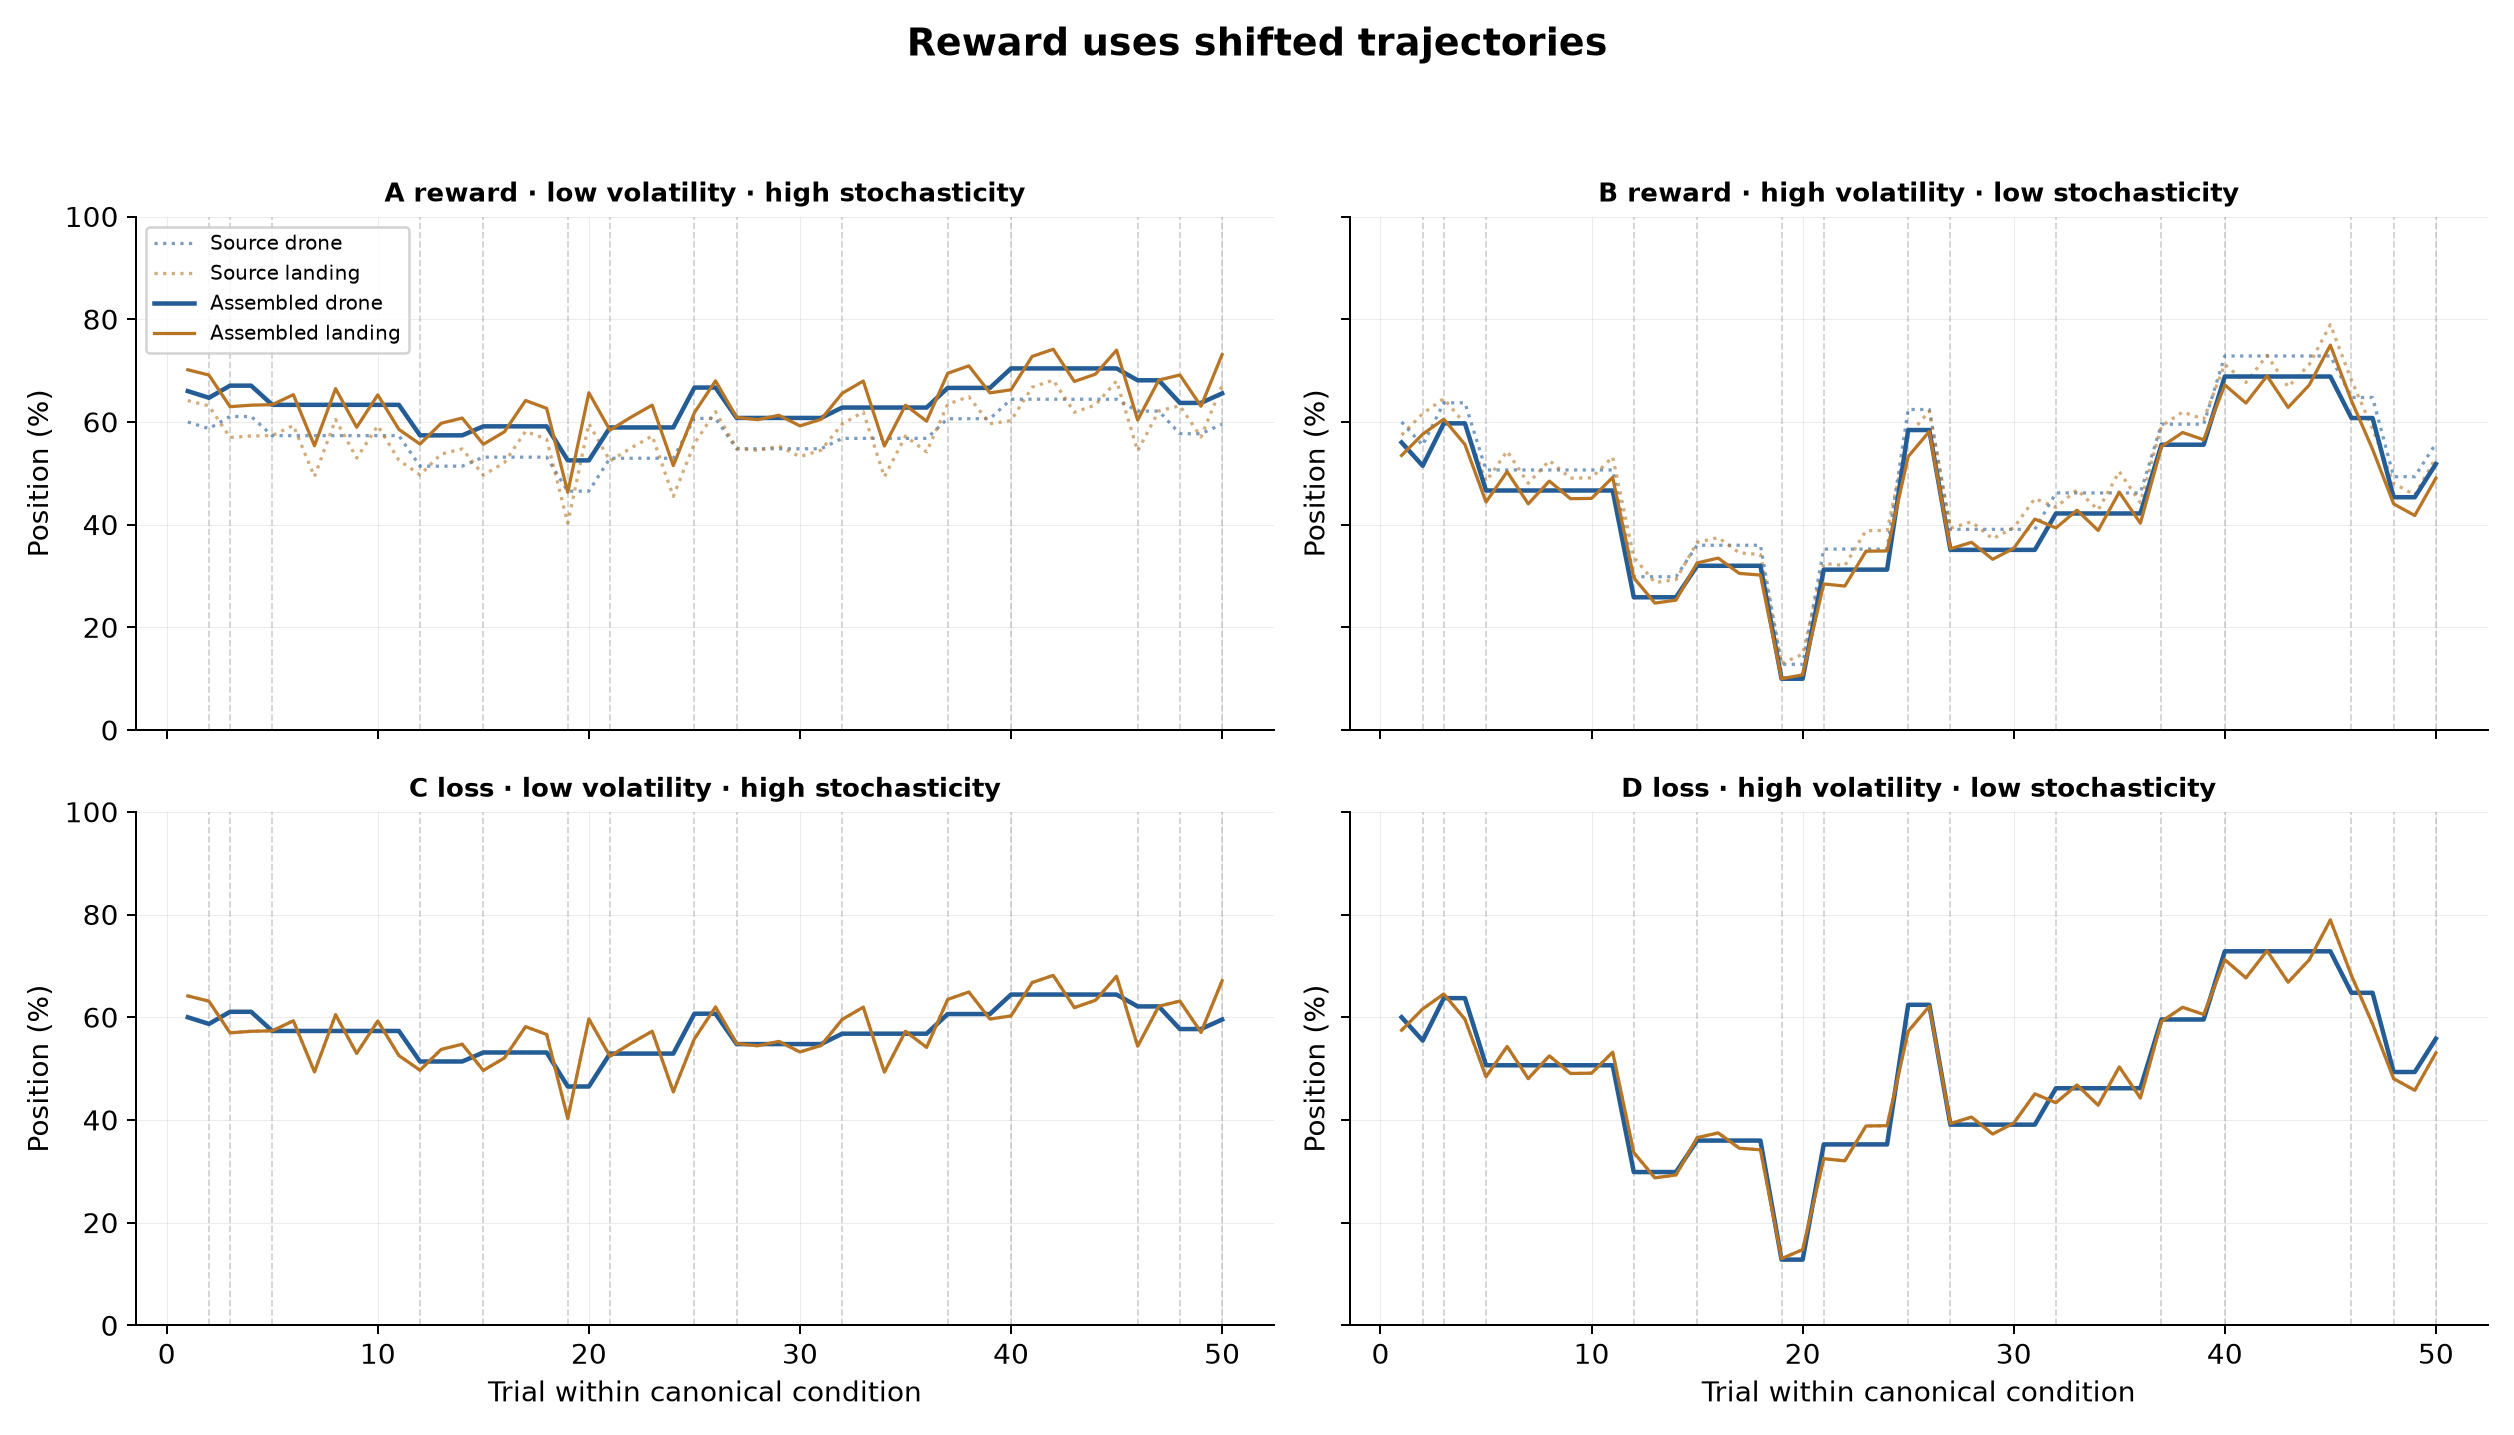

Both source-executed trajectory assignments exported.


In [3]:
for variant in runtime_variants:
    assert np.shape(variant['drone']) == (4,50)
    assert np.shape(variant['landing']) == (4,50)
    assert np.isfinite(variant['drone']).all() and np.isfinite(variant['landing']).all()


def plot_trajectories(variant):
    reward_shifted = variant['reward_uses_shifted_sequences']
    fig,axes = plt.subplots(2,2,figsize=(14,8),sharex=True,sharey=True)
    fig.suptitle('Reward uses shifted trajectories' if reward_shifted else 'Loss uses shifted trajectories',
                 fontsize=15,fontweight='bold')
    t=np.arange(1,51)
    for idx,ax in enumerate(axes.flat):
        row=variant['metrics'][idx]
        for cp in row['change_point_trials']:
            ax.axvline(cp,color='#999',ls='--',lw=.7,alpha=.45)
        ax.plot(t,variant['base_drone'][idx],ls=':',lw=1.3,color='#245d96',alpha=.6,label='Source drone')
        ax.plot(t,variant['base_landing'][idx],ls=':',lw=1.3,color='#b77525',alpha=.6,label='Source landing')
        ax.plot(t,variant['drone'][idx],lw=1.8,color='#245d96',label='Assembled drone')
        ax.plot(t,variant['landing'][idx],lw=1.3,color='#b77525',label='Assembled landing')
        ax.set_title(f"{chr(65+idx)} {row['valence']} · {row['vol_level']} volatility · {row['stc_level']} stochasticity",fontsize=10.5)
        ax.set_ylim(0,100)
        ax.set_ylabel('Position (%)')
        if idx>=2: ax.set_xlabel('Trial within canonical condition')
        if idx==0: ax.legend(fontsize=8,framealpha=.85)
    fig.tight_layout(rect=[0,0,1,.94])
    save_fig(fig,'trajectories_reward_shifted_'+str(reward_shifted).lower(),category='game',also_html=True)
    display(fig)
    plt.close(fig)

for variant in runtime_variants:
    plot_trajectories(variant)
print('Both source-executed trajectory assignments exported.')


## Measured signal and noise

Every canonical condition has 15 changes at the same trial positions. Volatility differs in the size of those changes, not their count. The audit reports movement across all 49 transitions and movement among the 15 actual changes separately. Stochasticity is measured as mean absolute drone to landing distance.

Labels were corrected in version `trajectory-aligned-v2-20261104` without changing the scientific series. Historical records retain their original labels and require version aware analysis.


,assignment,condition,valence,volatility,stochasticity,transitions,changes,mean_all_transitions,mean_nonzero_changes,mean_landing_distance
0,Loss shifted,A,reward,low,high,49,15,1.2247,4.0006,3.3875
1,Loss shifted,B,reward,high,low,49,15,4.3404,14.1787,2.5083
2,Loss shifted,C,loss,low,high,49,15,1.2247,4.0006,3.3875
3,Loss shifted,D,loss,high,low,49,15,4.2918,14.0200,2.4808
4,Reward shifted,A,reward,low,high,49,15,1.2247,4.0006,3.3875
5,Reward shifted,B,reward,high,low,49,15,4.2918,14.0200,2.4808
6,Reward shifted,C,loss,low,high,49,15,1.2247,4.0006,3.3875
7,Reward shifted,D,loss,high,low,49,15,4.3404,14.1787,2.5083


All 8 canonical condition assignments match both measured movement and measured landing distance.
Every nonzero change occurs at trials [2, 3, 5, 12, 15, 19, 21, 25, 27, 32, 37, 40, 46, 48, 50]


  ✓ game_trials/change_point_map.png + .pdf
  ✓ game_trials/change_point_map.html


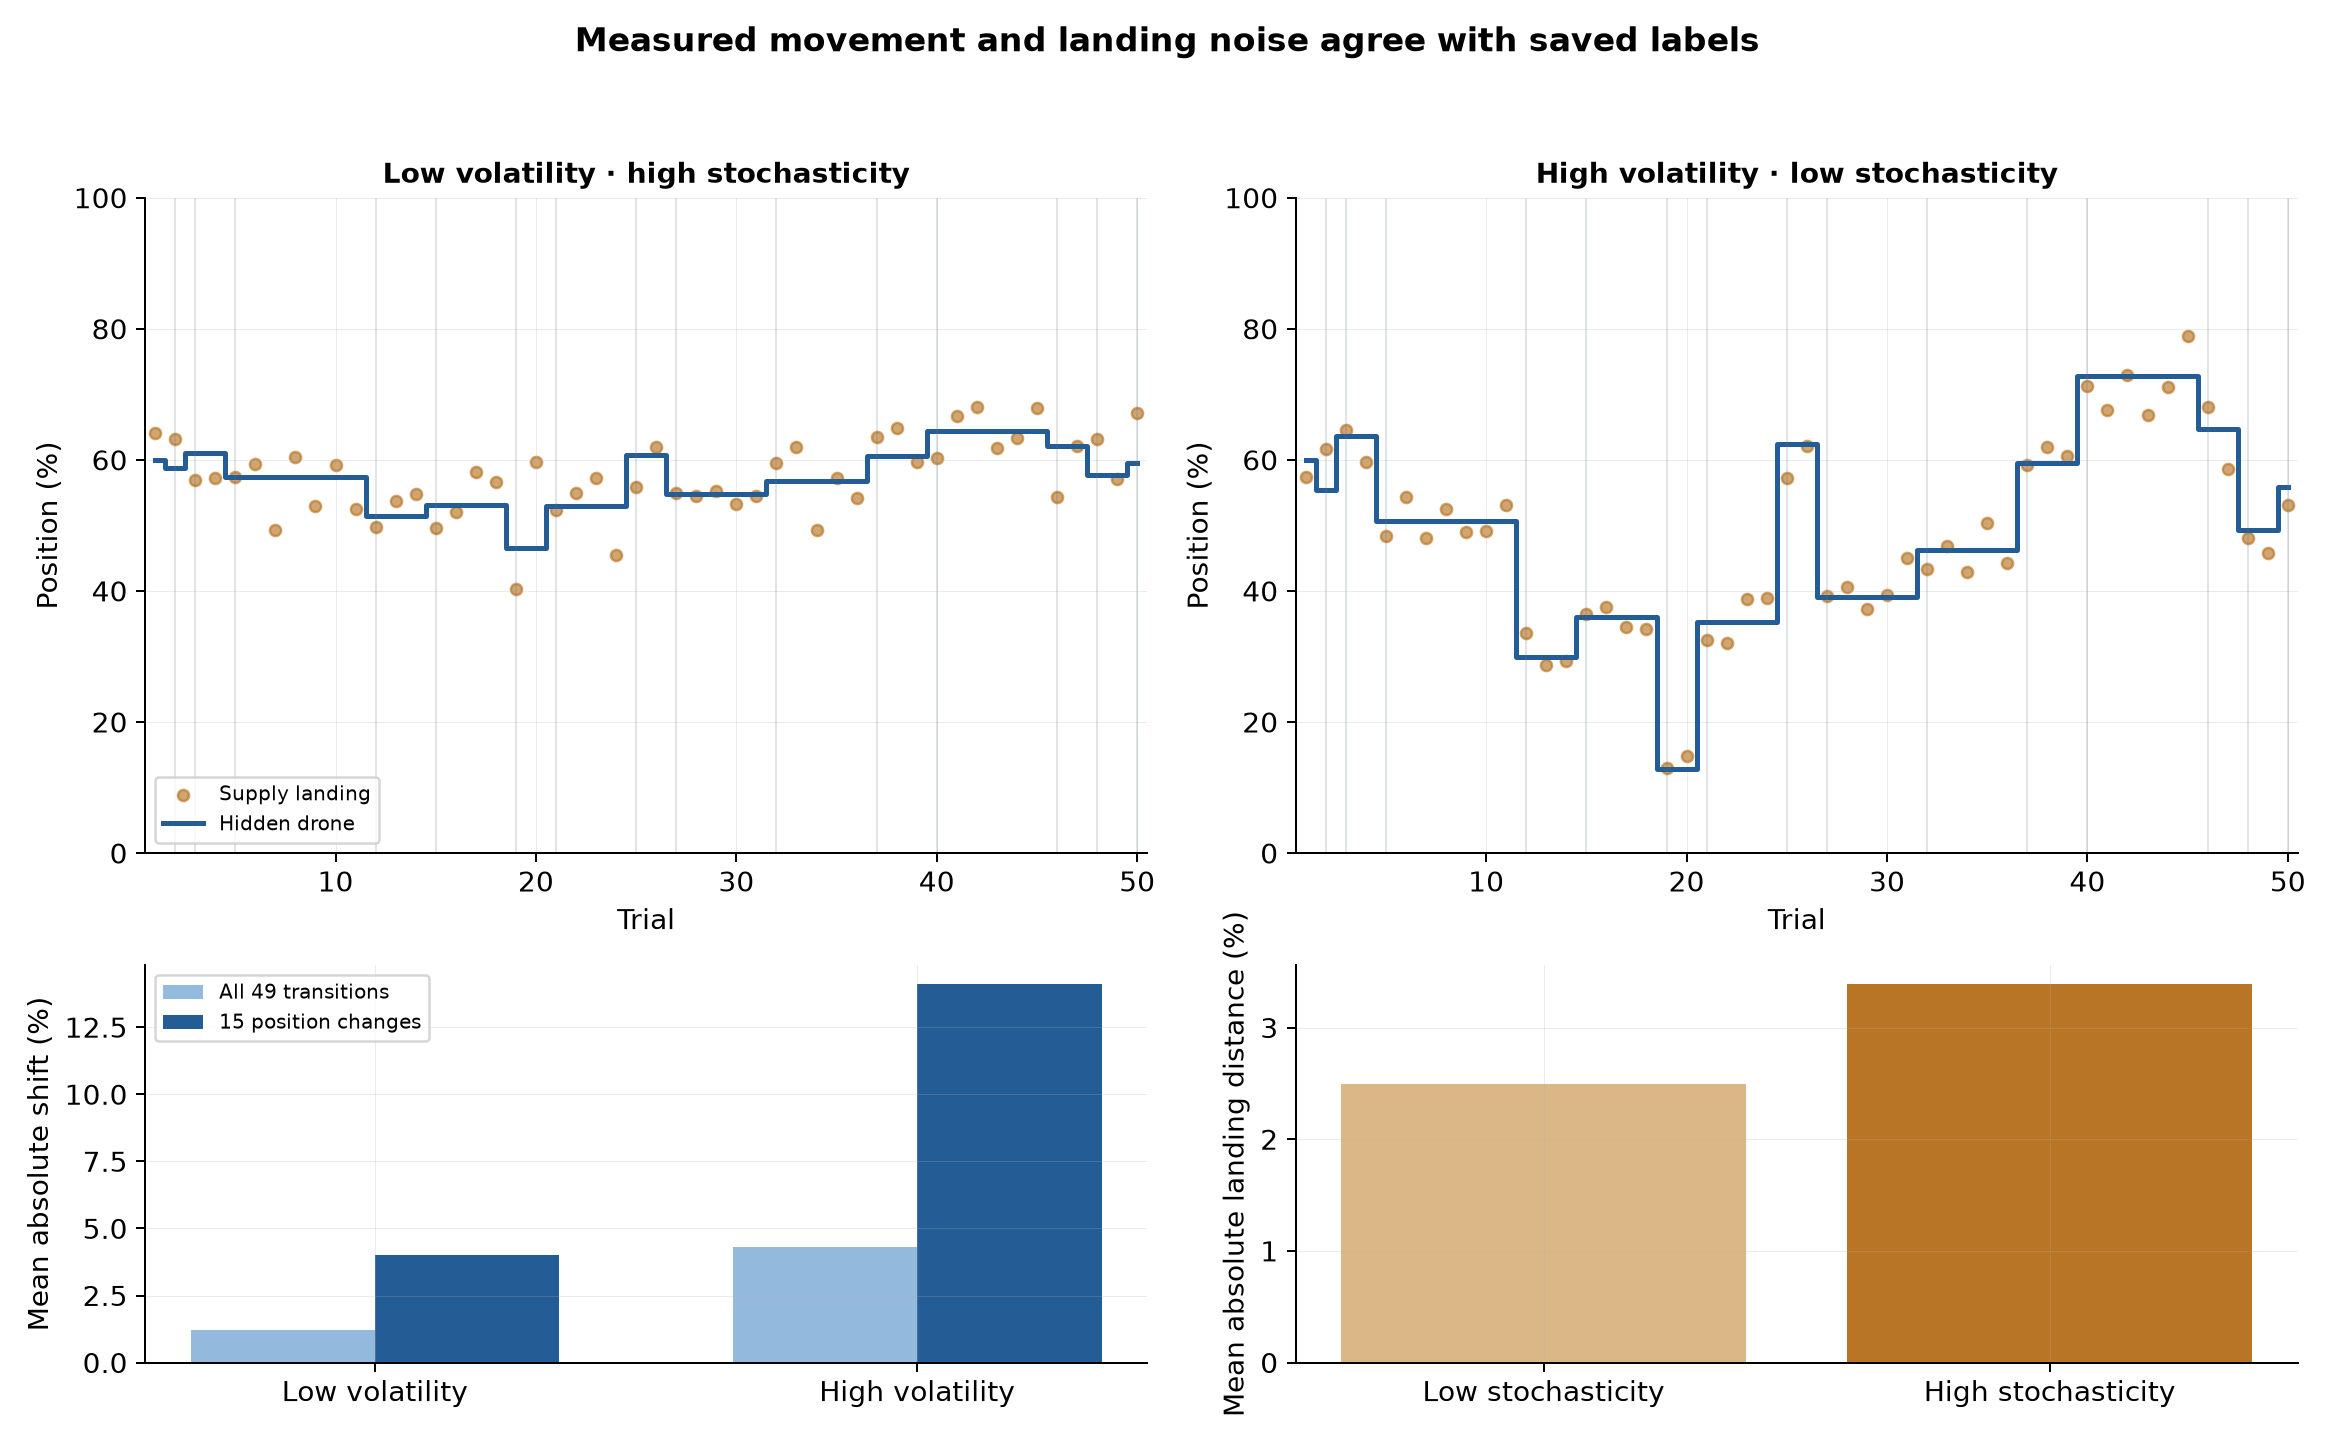

In [4]:
rows=[]
for variant in runtime_variants:
    assignment='Reward shifted' if variant['reward_uses_shifted_sequences'] else 'Loss shifted'
    for idx,row in enumerate(variant['metrics']):
        rows.append(dict(assignment=assignment,condition=chr(65+idx),valence=row['valence'],
            volatility=row['vol_level'],stochasticity=row['stc_level'],
            transitions=row['n_transitions'],changes=row['n_position_changes'],
            mean_all_transitions=row['mean_absolute_drone_shift'],
            mean_nonzero_changes=row['mean_absolute_nonzero_drone_shift'],
            mean_landing_distance=row['mean_absolute_drone_to_landing_distance']))
vol_df=pd.DataFrame(rows)
display(vol_df.round(4))
expected_cps=[2,3,5,12,15,19,21,25,27,32,37,40,46,48,50]
for variant in runtime_variants:
    for row in variant['metrics']:
        assert row['change_point_trials']==expected_cps
        assert row['n_transitions']==49 and row['n_position_changes']==15
    for valence in ['reward','loss']:
        grouped=[r for r in variant['metrics'] if r['valence']==valence]
        low=next(r for r in grouped if r['vol_level']=='low')
        high=next(r for r in grouped if r['vol_level']=='high')
        assert high['mean_absolute_nonzero_drone_shift']>low['mean_absolute_nonzero_drone_shift']
        assert high['mean_absolute_drone_shift']>low['mean_absolute_drone_shift']
        assert low['mean_absolute_drone_to_landing_distance']>high['mean_absolute_drone_to_landing_distance']
print('All 8 canonical condition assignments match both measured movement and measured landing distance.')
print('Every nonzero change occurs at trials',expected_cps)

fig,axes=plt.subplots(2,2,figsize=(13,8),gridspec_kw={'height_ratios':[1.65,1]})
variant=reference_design
t=np.arange(1,51)
for idx,ax in enumerate(axes[0]):
    row=variant['metrics'][idx]
    ax.scatter(t,variant['landing'][idx],s=20,color='#b77525',alpha=.65,label='Supply landing')
    ax.step(t,variant['drone'][idx],where='mid',lw=2,color='#245d96',label='Hidden drone')
    for cp in row['change_point_trials']:
        ax.axvline(cp,color='#64748b',alpha=.2,lw=.8)
    ax.set_title(f"{row['vol_level'].capitalize()} volatility · {row['stc_level']} stochasticity",fontsize=11)
    ax.set(xlabel='Trial',ylabel='Position (%)',xlim=(.5,50.5),ylim=(0,100))
    if idx==0: ax.legend(fontsize=8,loc='lower left')
summary=vol_df.groupby('volatility').agg(all_transitions=('mean_all_transitions','mean'),
        position_changes=('mean_nonzero_changes','mean'),landing_distance=('mean_landing_distance','mean')).reindex(['low','high'])
x=np.arange(2);w=.34
axes[1,0].bar(x-w/2,summary.all_transitions,w,label='All 49 transitions',color='#93b9dc')
axes[1,0].bar(x+w/2,summary.position_changes,w,label='15 position changes',color='#245d96')
axes[1,0].set(xticks=x,xticklabels=['Low volatility','High volatility'],ylabel='Mean absolute shift (%)')
axes[1,0].legend(fontsize=8)
noise=vol_df.groupby('stochasticity').mean_landing_distance.mean().reindex(['low','high'])
axes[1,1].bar(x,noise,color=['#dbb788','#b77525'])
axes[1,1].set(xticks=x,xticklabels=['Low stochasticity','High stochasticity'],ylabel='Mean absolute landing distance (%)')
fig.suptitle('Measured movement and landing noise agree with saved labels',fontweight='bold')
fig.tight_layout(rect=[0,0,1,.95])
save_fig(fig,'change_point_map',category='game',also_html=True)
display(fig)
plt.close(fig)


## Drop-object distribution and feedback audit

,fragment,h_offset,duration_ms
0,0,-4.25,350
1,1,-3.00,400
2,2,-1.75,500
3,3,-0.75,550
4,4,-0.25,600
5,5,0.25,600
6,6,0.75,600
7,7,1.75,500
8,8,3.00,500
9,9,4.25,400


✓ 10 fragments, matching lengths, all finite.


,captured,reward_fb,loss_fb
0,0,0,-10
1,1,1,-9
2,2,2,-8
3,3,3,-7
4,4,4,-6
5,5,5,-5
6,6,6,-4
7,7,7,-3
8,8,8,-2
9,9,9,-1


  ✓ game_trials/drop_object_distribution.png + .pdf
  ✓ game_trials/drop_object_distribution.html


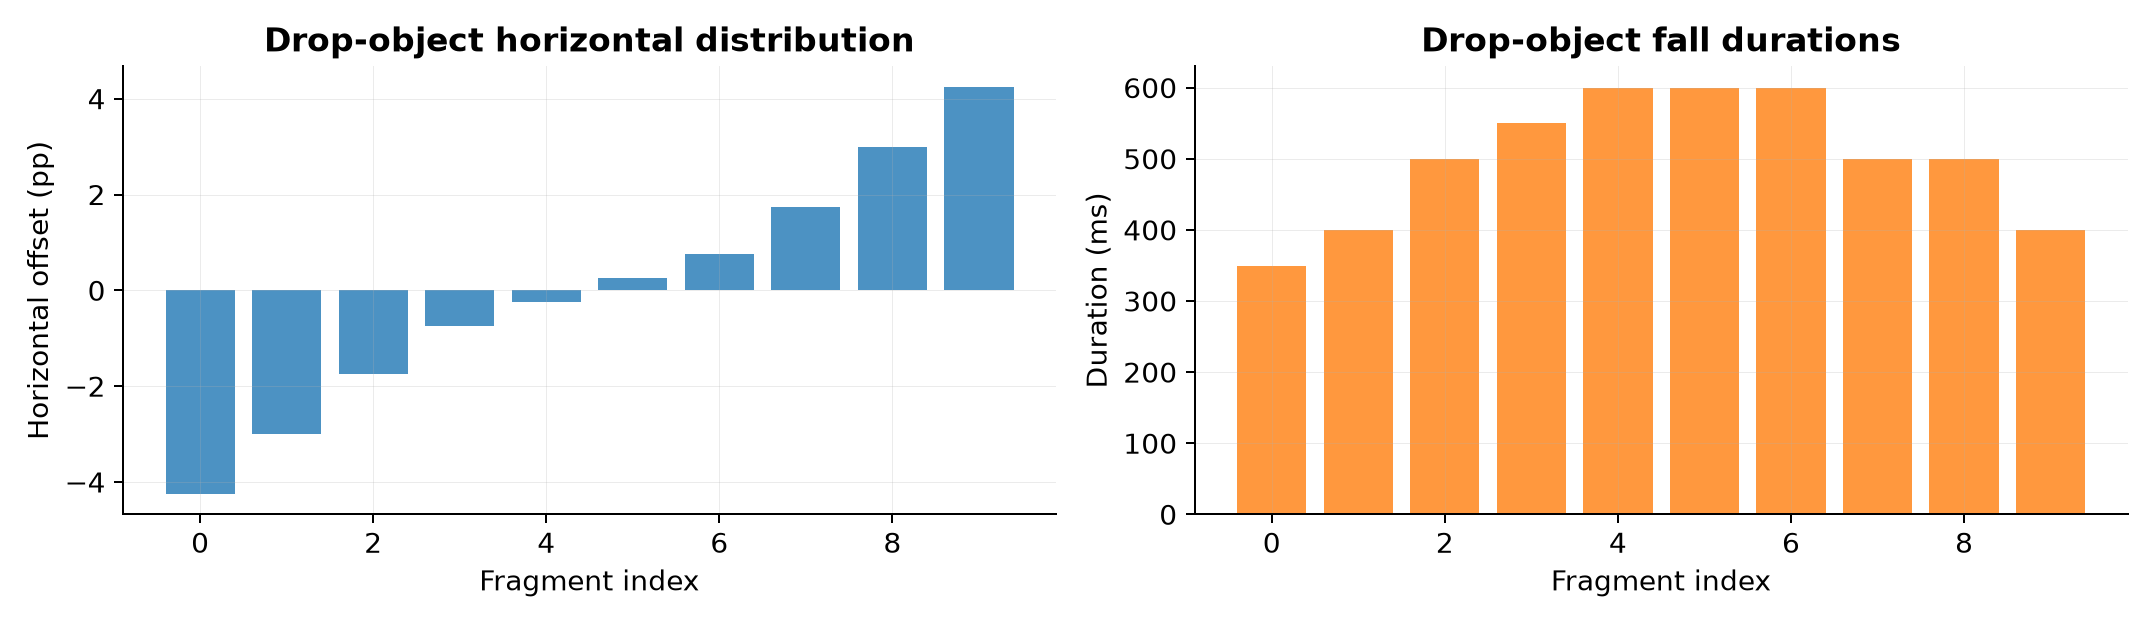

  ✓ game_trials/drop_object_distribution_feedback_audit.html


In [5]:
src_drop = details_src if details_src else stimuli_src
drop_dist = parse_js_flat_array(src_drop, "drop_obj_distribution_default")
drop_dur  = parse_js_flat_array(src_drop, "drop_obj_duration_default")

drop_df = pd.DataFrame({"fragment": range(len(drop_dist)),
    "h_offset": drop_dist, "duration_ms": [int(d) for d in drop_dur]})
display(drop_df)

assert len(drop_dist)==10 and len(drop_dur)==10
assert all(np.isfinite(drop_dist)) and all(np.isfinite(drop_dur))
print("\u2713 10 fragments, matching lengths, all finite.")

fb_df = pd.DataFrame({"captured": range(11),
    "reward_fb": range(11), "loss_fb": [c-10 for c in range(11)]})
display(fb_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
ax1.bar(drop_df.fragment, drop_df.h_offset, color="#1f77b4", alpha=0.8)
ax1.set_xlabel("Fragment index"); ax1.set_ylabel("Horizontal offset (pp)")
ax1.set_title("Drop-object horizontal distribution", fontweight="bold")
ax2.bar(drop_df.fragment, drop_df.duration_ms, color="#ff7f0e", alpha=0.8)
ax2.set_xlabel("Fragment index"); ax2.set_ylabel("Duration (ms)")
ax2.set_title("Drop-object fall durations", fontweight="bold")
fig.tight_layout()
save_fig(fig, "drop_object_distribution", category="game", also_html=True)
plt.show()

save_html(
    styled_table_css("dropfb") + '<div id="dropfb">' +
    "<table><caption>Drop-object distribution</caption>" + drop_df.to_html(index=False) + "</table>" +
    "<table><caption>Reward / loss feedback mapping</caption>" + fb_df.to_html(index=False) + "</table></div>", "drop_object_distribution_feedback_audit.html", category="game")

## Reward scoring function

Step-function thresholds parsed directly from `trial.js`. Left panel: catch count vs distance. Right panel: 50k Monte Carlo L/R symmetry check.

  ✓ game_trials/scoring_function.png + .pdf


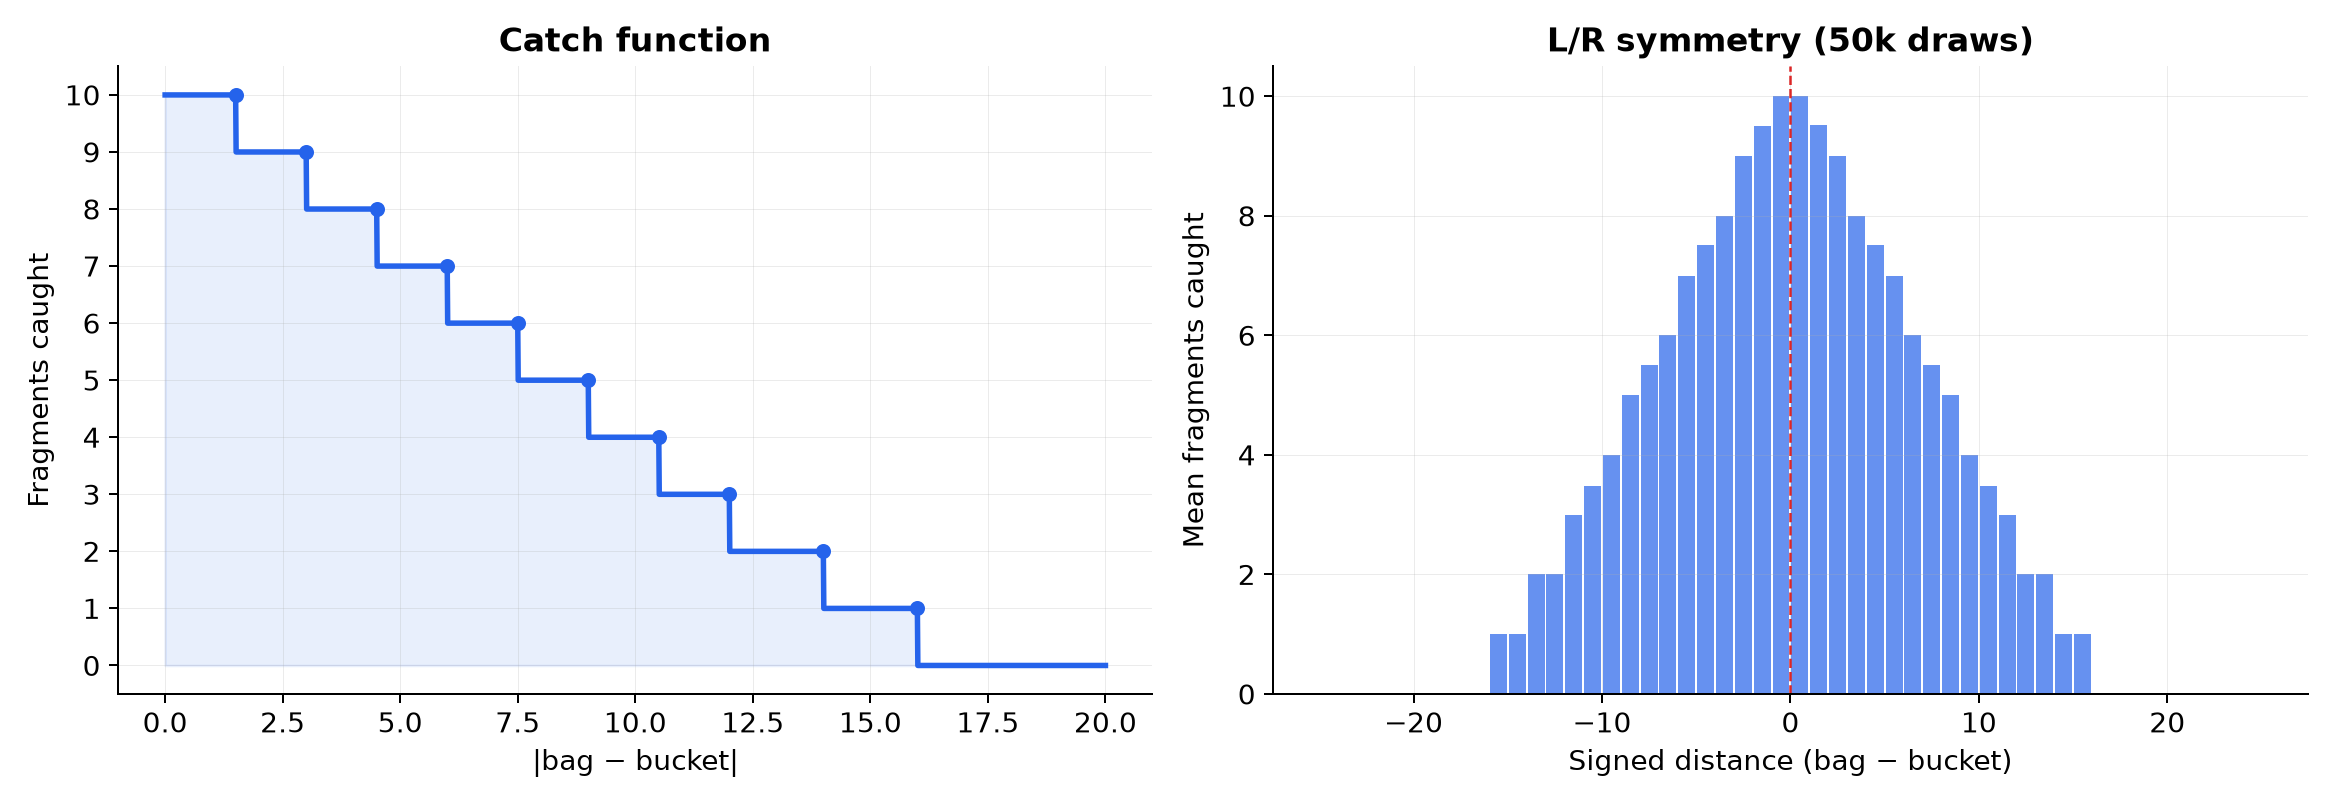

Left: 1.4712, Right: 1.4837, Δ=0.0125
✅ No asymmetry.


In [6]:
thresholds = parse.capture_thresholds(trial_src)
def compute_capture(d):
    for t, c in thresholds[:-1]:
        if d <= t: return c
    return 0

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
d = np.linspace(0, 20, 2001)
scores = [compute_capture(x) for x in d]
axes[0].plot(d, scores, lw=2.2, color='#2563eb')
axes[0].fill_between(d, scores, alpha=.1, color='#2563eb')
for t, c in thresholds[:-1]:
    axes[0].plot(t, c, 'o', ms=5, color='#2563eb', zorder=5)
axes[0].set_xlabel('|bag − bucket|'); axes[0].set_ylabel('Fragments caught')
axes[0].set_title('Catch function'); axes[0].set_yticks(range(0, 11))

np.random.seed(42)
bag = np.random.uniform(8, 92, 50000)
bkt = np.random.uniform(8, 92, 50000)
signed = bag - bkt
caught = np.array([compute_capture(abs(x)) for x in signed])
bins = np.arange(-25, 26, 1)
idx = np.digitize(signed, bins)
means = [caught[idx==i].mean() if (idx==i).sum()>0 else np.nan for i in range(1, len(bins))]
centres = (bins[:-1] + bins[1:]) / 2
axes[1].bar(centres, means, width=.9, color='#2563eb', alpha=.7)
axes[1].axvline(0, color='#dc2626', lw=1, ls='--')
axes[1].set_xlabel('Signed distance (bag − bucket)')
axes[1].set_ylabel('Mean fragments caught')
axes[1].set_title('L/R symmetry (50k draws)')
plt.tight_layout()
save_fig(fig, 'scoring_function', 'game')
plt.show()

left_m = caught[signed < -2].mean(); right_m = caught[signed > 2].mean()
print(f'Left: {left_m:.4f}, Right: {right_m:.4f}, Δ={abs(left_m-right_m):.4f}')
print('✅ No asymmetry.' if abs(left_m-right_m) < .05 else '⚠ Investigate.')